In [1]:
import palantir
import scanpy as sc
import sys
import matplotlib.pyplot as plt
import scipy.stats as st
import os
import numpy as np
import cellrank as cr
import mplscience
import scvelo as scv
sys.path.append('/home/blattms1/projects/gapfill/4CL_JAK2/likelihood_model/src/')
import utils as lm_utils
import pandas as pd

In [2]:
adata_path = '/data1/lareauc/users/blattms/gapfill/wta_adata/tRNA_HSC_differentiation.h5ad'
adata = sc.read_h5ad(adata_path)


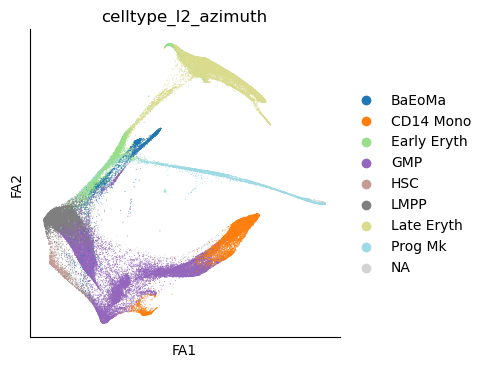

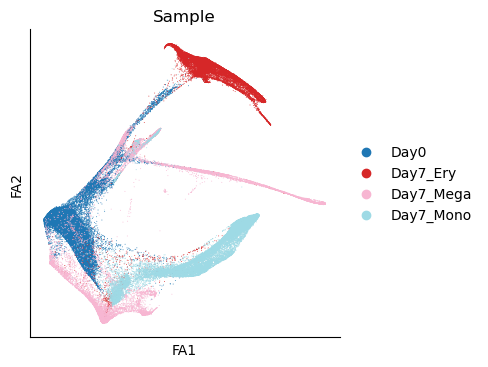

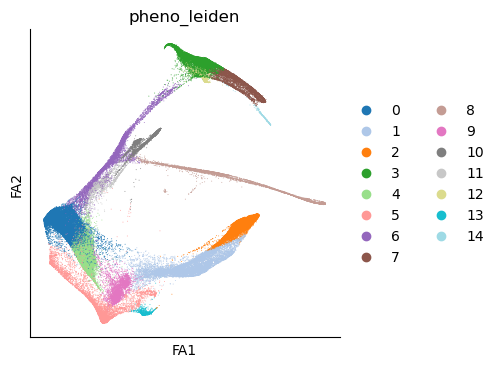

In [3]:
# ## save for azimuth
# sc.AnnData(X = adata.layers['raw_data'], 
#                  obs = pd.DataFrame({'phenograph_label': adata.obs['pheno_leiden'].astype('float')}, 
#                                     index = adata.obs.index),
#                  var = pd.DataFrame(index = adata.var.index)).write_h5ad(adata_path.replace('.h5ad', '_raw_counts.h5ad'))

### read in azimuth predictions for comparison
azimuth_labels = pd.read_csv('tRNA_HSC_differentiation_raw_counts_azimuth_preds.csv', index_col=0)
azimuth_labels.columns = azimuth_labels.columns + '_azimuth'

for col in azimuth_labels.columns:
    if col in adata.obs.columns:
        print('Column ' + col + ' already exists in adata.obs. Dropping it.')
        adata.obs.drop(columns=[col], inplace=True)
adata.obs = adata.obs.merge(azimuth_labels, left_index=True, right_index=True, how='left')

cell_type_counts = adata.obs['celltype_l2_azimuth'].value_counts(normalize=True)
cell_type_counts = cell_type_counts[cell_type_counts > 0.01]
adata.obs.loc[~adata.obs['celltype_l2_azimuth'].isin(cell_type_counts.index), 'celltype_l2_azimuth'] = None
adata.obs['celltype_l2_azimuth'] = adata.obs['celltype_l2_azimuth'].astype('category')
adata.obs['celltype_l2_azimuth'] = adata.obs['celltype_l2_azimuth'].cat.remove_unused_categories()
sc.pl.draw_graph(adata, color = 'celltype_l2_azimuth', palette = 'tab20')
sc.pl.draw_graph(adata, color = 'Sample')
sc.pl.draw_graph(adata, color = 'pheno_leiden', palette = 'tab20')


In [4]:
for sample in adata.obs['Sample'].unique():
    cell_types = adata[adata.obs['Sample'] == sample].obs['celltype_l2_azimuth'].value_counts(normalize=True)
    print(f'Sample: {sample}')
    print(cell_types[cell_types > 0.01])

Sample: Day0
celltype_l2_azimuth
LMPP           0.397643
GMP            0.374279
Early Eryth    0.119849
BaEoMa         0.043989
Prog Mk        0.031871
Late Eryth     0.029049
Name: proportion, dtype: float64
Sample: Day7_Ery
celltype_l2_azimuth
Late Eryth     0.899887
GMP            0.042553
Early Eryth    0.036494
BaEoMa         0.011836
Name: proportion, dtype: float64
Sample: Day7_Mega
celltype_l2_azimuth
Prog Mk        0.262235
GMP            0.259126
BaEoMa         0.198788
Early Eryth    0.087837
HSC            0.084409
CD14 Mono      0.067033
LMPP           0.034114
Name: proportion, dtype: float64
Sample: Day7_Mono
celltype_l2_azimuth
CD14 Mono    0.495874
GMP          0.483521
BaEoMa       0.013131
Name: proportion, dtype: float64


In [5]:
# Run diffusion maps
dm_res = palantir.utils.run_diffusion_maps(adata, n_components=10)


Text(0, 0.5, 'Eigen-Values')

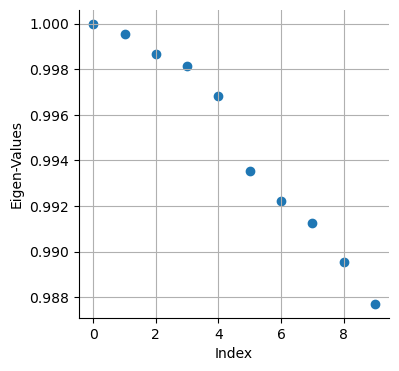

In [6]:
# Plot eigenvalues to visualize gap
plt.scatter(range(len(adata.uns['DM_EigenValues'])), adata.uns['DM_EigenValues'])
plt.grid('on')
plt.xlabel('Index')
plt.ylabel('Eigen-Values')

In [7]:
ms_data = palantir.utils.determine_multiscale_space(adata)
adata.obsm['DM_EigenVectors_multiscaled'].shape

(72601, 4)

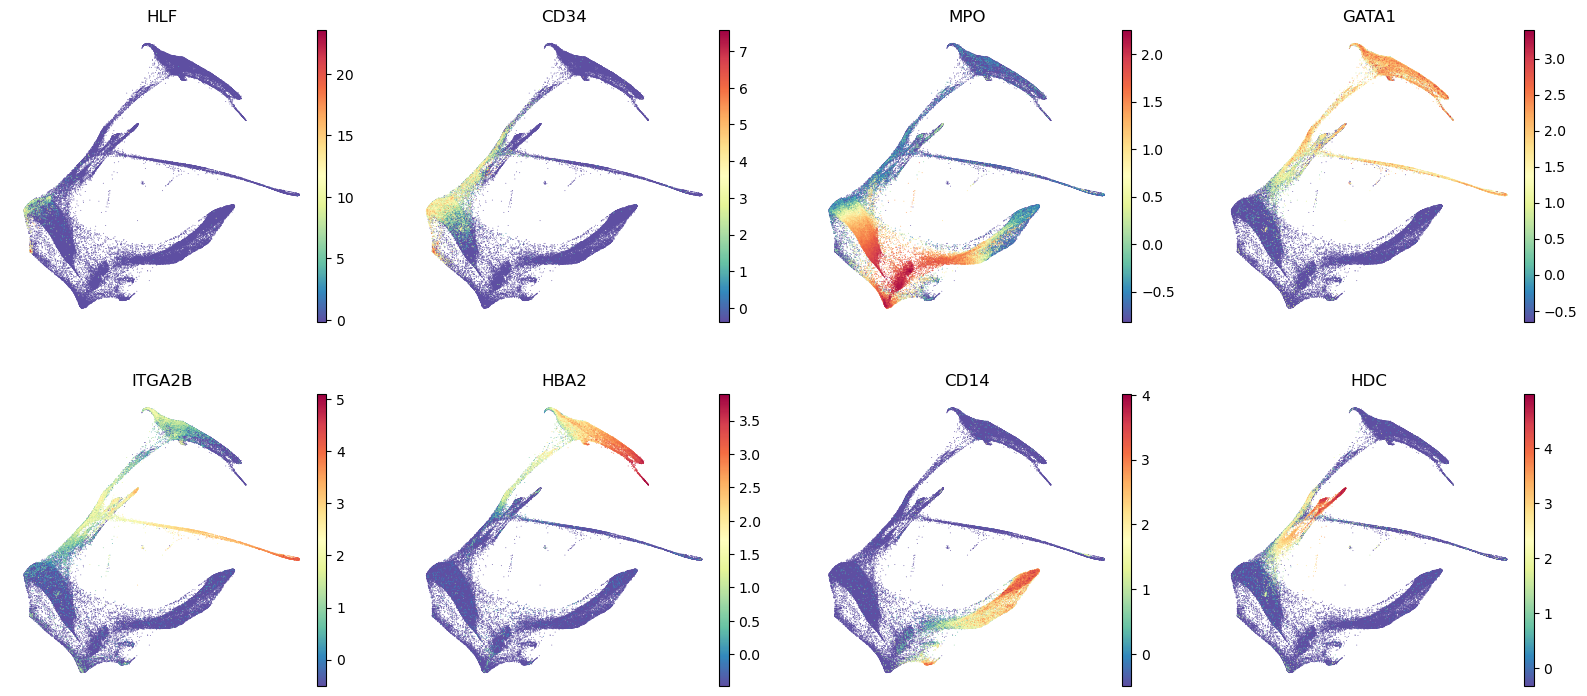

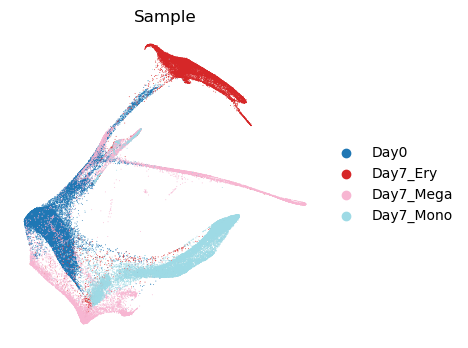

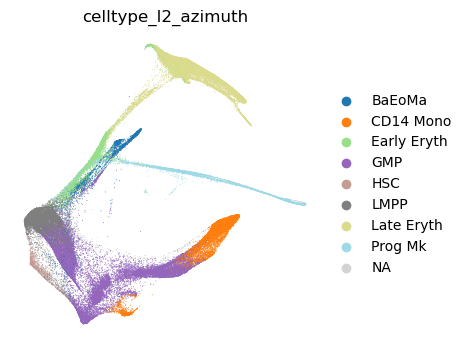

In [8]:
sc.pl.embedding(
    adata,
    basis="X_draw_graph_fa",
    layer="zs_norm_log",
    color=["HLF","CD34", "MPO", "GATA1","ITGA2B","HBA2","CD14","HDC"],
    frameon=False, ncols=4, show=False
)
plt.savefig('figures/marker_genes_FDL.png', dpi=300, bbox_inches='tight')
plt.show()

sc.pl.embedding(
    adata,
    basis="X_draw_graph_fa",
    color="Sample",
    frameon=False, show=False
)
plt.savefig('figures/Samples_FDL.png', dpi=300, bbox_inches='tight')

sc.pl.embedding(
    adata,
    basis="X_draw_graph_fa",
    color="celltype_l2_azimuth",
    frameon=False, show=False, palette='tab20'
)
plt.savefig('figures/azimuth_cell_type_FDL.png', dpi=300, bbox_inches='tight')

plt.show()

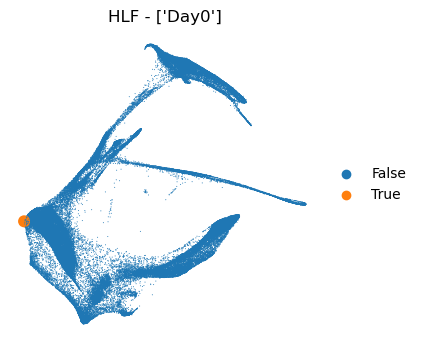

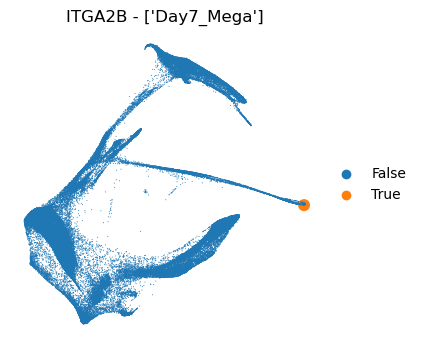

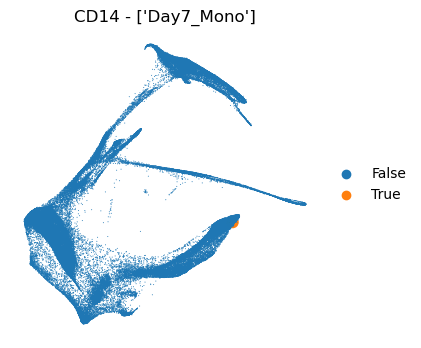

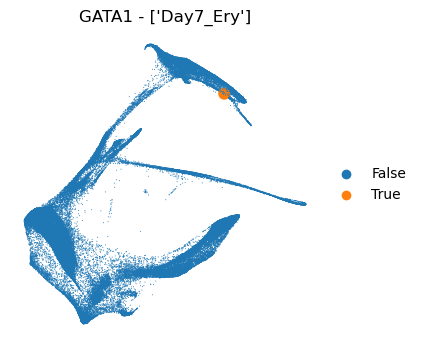

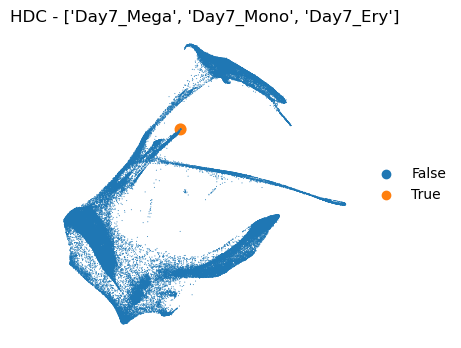

In [ ]:
### get start cell and terminal states for palantir

cell_ids = []
marker_genes = ['HLF','ITGA2B', 'CD14', 'GATA1', 'HDC']
samples = [['Day0'],['Day7_Mega'],['Day7_Mono'],['Day7_Ery'],['Day7_Mega','Day7_Mono','Day7_Ery']]

for i in range(len(marker_genes)):
    marker_gene = marker_genes[i]
    sample = samples[i]
    expression = adata[adata.obs['Sample'].isin(sample)][:, marker_gene].layers['magic_on_pca_imputed_data'].toarray().flatten()
    # Find the indices of the cells with the highest expression
    top_cells_indices = np.argsort(expression)[-1:]  # Top cell with highest expression
    # Get the cell barcodes for these indices
    top_cells = adata[adata.obs['Sample'].isin(sample)].obs.index[top_cells_indices]

    adata.obs['highlight_mask'] = adata.obs.index.isin(top_cells)
    adata.obs['highlight_mask'] = adata.obs['highlight_mask'].astype('category')
    sc.pl.draw_graph(adata, color='highlight_mask', size=adata.obs['highlight_mask'].map({True: 300, False: 2}), title = f'{marker_gene} - {sample}', frameon=False)
    cell_ids.append(top_cells[0])

Sampling and flocking waypoints...
Time for determining waypoints: 0.055881961186726885 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.5068088889122009 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


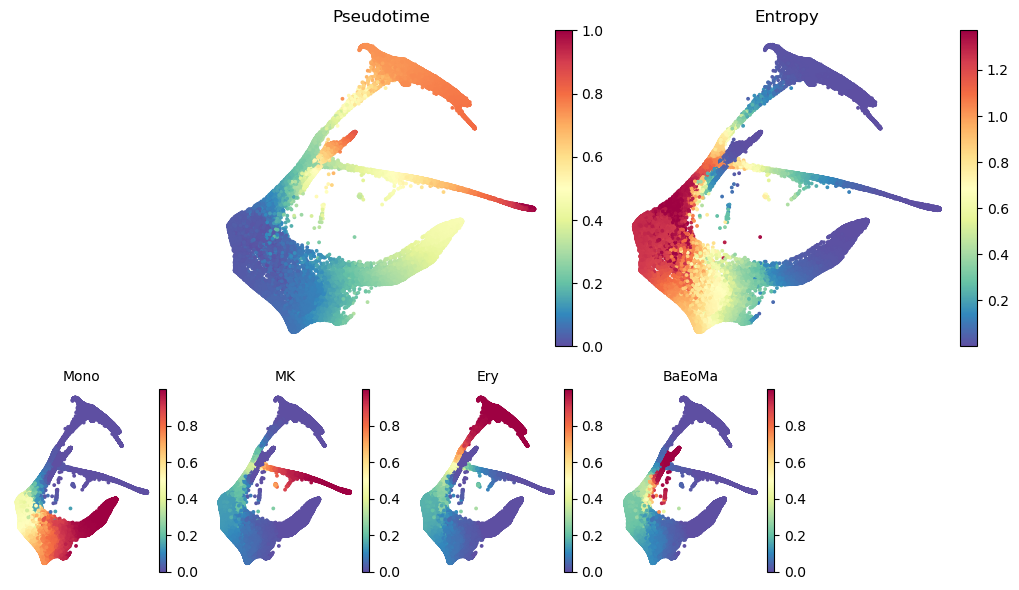

In [ ]:
## run palantir with 4 terminal states
start_cell = cell_ids[0]
terminal_states = pd.Series(
    ["MK", "Mono", "Ery","BaEoMa"],
    index=cell_ids[1:5],
)

pr_res = palantir.core.run_palantir(
    adata, start_cell, num_waypoints=500, terminal_states=terminal_states
)

palantir.plot.plot_palantir_results(adata, s=3, embedding_basis = 'X_draw_graph_fa')
plt.savefig('figures/palantir_trajectory_figures/all_cells_4_terminal_states.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
### save FDL and pseudotime
FDL_coords = pd.DataFrame(adata.obsm['X_draw_graph_fa'], index = adata.obs.index, columns = ['FA1','FA2'])
FDL_coords.to_csv('/data1/lareauc/projects/trnaseq/20250624_Experiment17_CD34culture/WTA_trajectory/FDL_coordinates.csv')
adata.obsm['palantir_fate_probabilities'].to_csv('/data1/lareauc/projects/trnaseq/20250624_Experiment17_CD34culture/WTA_trajectory/palantir_fate_probabilities.csv')
adata.obs[['palantir_pseudotime','palantir_entropy','celltype_l2_azimuth']].to_csv('/data1/lareauc/projects/trnaseq/20250624_Experiment17_CD34culture/WTA_trajectory/pseudotime_entropy_cell_types.csv')

Sampling and flocking waypoints...
Time for determining waypoints: 0.05784837404886881 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.4201465884844462 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


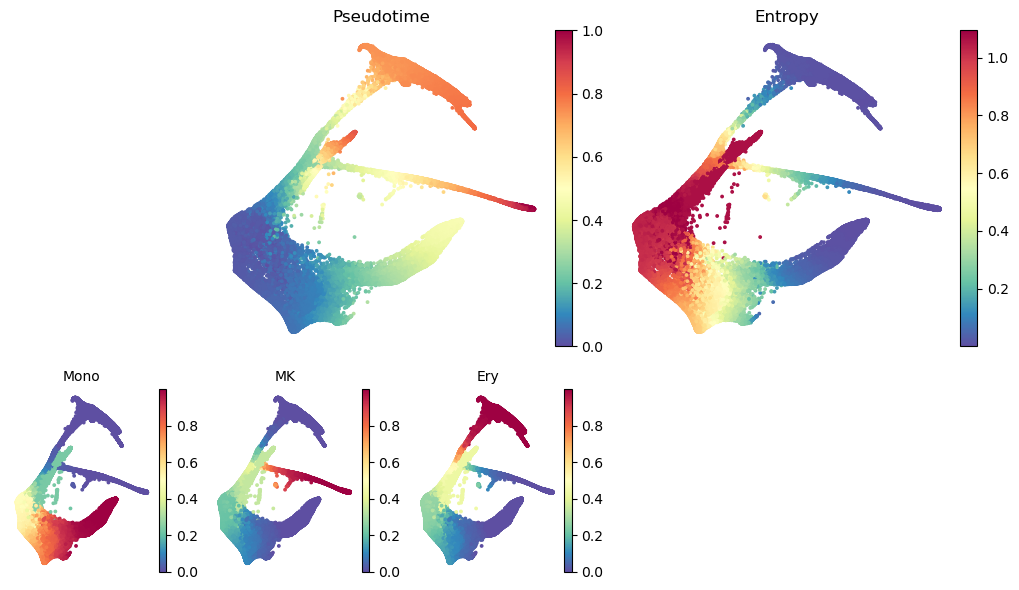

In [ ]:
### run trajectory with 3 terminal states

start_cell = cell_ids[0]
terminal_states = pd.Series(
    ["MK", "Mono", "Ery"],
    index=cell_ids[1:4],
)

pr_res = palantir.core.run_palantir(
    adata, start_cell, num_waypoints=500, terminal_states=terminal_states
)

palantir.plot.plot_palantir_results(adata, s=3, embedding_basis = 'X_draw_graph_fa')
plt.savefig('figures/palantir_trajectory_figures/all_cells_3_terminal_states.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
### find cell clusters to exclude when omitting BaEoMa cells
adata[adata.obs['celltype_l2_azimuth'] == 'BaEoMa'].obs['pheno_leiden'].value_counts()

pheno_leiden
10    2726
11     871
4      119
6      107
5      102
0       27
9       22
3        1
Name: count, dtype: int64

Sampling and flocking waypoints...
Time for determining waypoints: 0.05333499511082967 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.39789912700653074 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


/data1/lareauc/users/blattms/miniconda3/envs/trajectory/lib/python3.13/site-packages/palantir/core.py:176: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data.obs[pseudo_time_key] = pseudotime


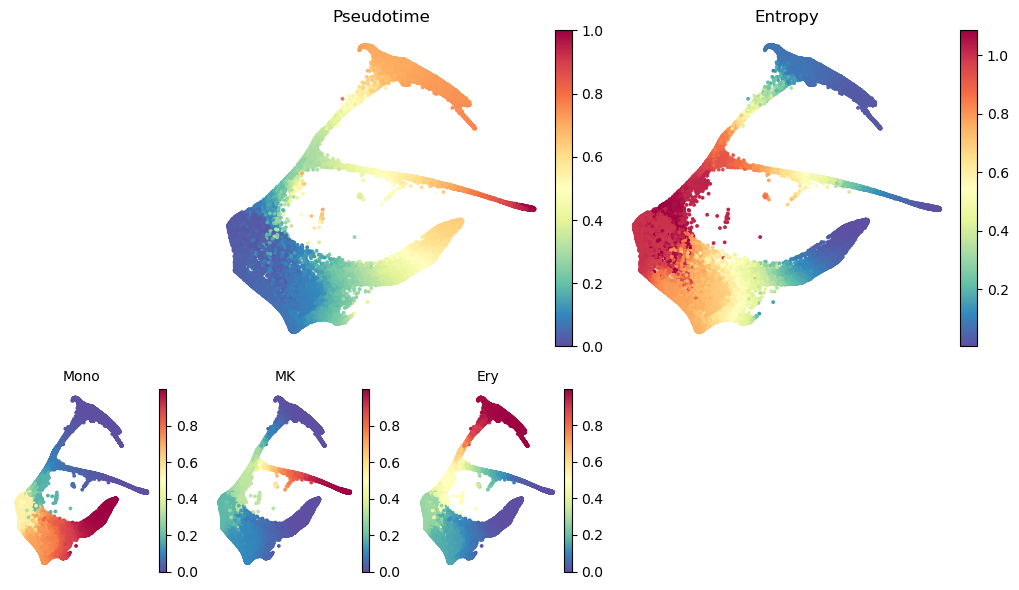

In [ ]:
### remove BaEoMa cells and run palantir with 3 terminal states

adata = adata[~adata.obs['pheno_leiden'].isin([10,11])]

start_cell = cell_ids[0]
terminal_states = pd.Series(
    ["MK", "Mono", "Ery"],
    index=cell_ids[1:4],
)

pr_res = palantir.core.run_palantir(
    adata, start_cell, num_waypoints=500, terminal_states=terminal_states
)

palantir.plot.plot_palantir_results(adata, s=3, embedding_basis = 'X_draw_graph_fa')
plt.savefig('figures/palantir_trajectory_figures/exclude_BaEoMa_3_terminal_states.png', dpi=300, bbox_inches='tight')
plt.show()

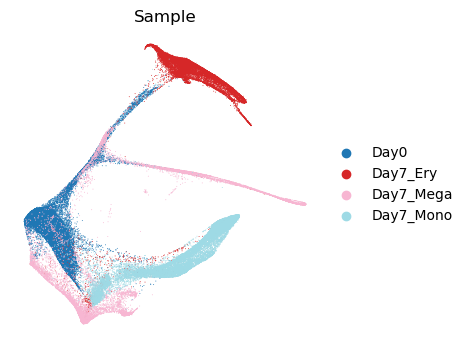

In [15]:
sc.pl.embedding(
    adata,
    basis="X_draw_graph_fa",
    color="Sample",
    frameon=False, show=False
)
plt.savefig('figures/Samples_exlude_BaEoMa_FDL.png', dpi=300, bbox_inches='tight')
